# This is the first go at the audiology model


In [1]:
import pandas as pd 
import numpy as np
df = pd.read_csv(r"C:\Users\joshh\Machine_Learning\Audiology_Project\Audio_Data.csv")
df.head()


,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,...,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat
0,0.332069,14/11/2025,0,95,90,0,85,0,75,100,...,0,80,0,75,85,110,105,105,HA,HA
1,0.332069,14/11/2025,10,0,50,0,65,0,70,65,...,0,60,0,70,70,65,0,0,HA,HA
2,0.999993,09/05/2012,10,0,15,0,0,0,0,0,...,0,0,0,0,0,0,0,0,No Treatment,No Treatment
3,0.999993,09/05/2012,0,0,25,0,20,0,20,20,...,0,20,0,20,0,20,0,0,No Treatment,No Treatment
4,0.999989,07/01/2025,10,0,0,0,0,0,65,65,...,0,65,0,65,0,0,0,0,No Treatment,No Treatment


In [2]:
df['Treatment Cat'].value_counts()

Treatment Cat
No Treatment    352616
HA               97289
BCI_MEI          20225
CI               19723
Name: count, dtype: int64

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 489853 entries, 0 to 489852
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unique PID        489853 non-null  float64
 1   INVESTDATE        489853 non-null  str    
 2   CURVE             489853 non-null  int64  
 3   R250C             489853 non-null  int64  
 4   R500C             489853 non-null  int64  
 5   R750C             489853 non-null  int64  
 6   R1000C            489853 non-null  int64  
 7   R1500C            489853 non-null  int64  
 8   R2000C            489853 non-null  int64  
 9   R3000C            489853 non-null  int64  
 10  R4000C            489853 non-null  int64  
 11  R6000C            489853 non-null  int64  
 12  R8000C            489853 non-null  int64  
 13  L250C             489853 non-null  int64  
 14  L500C             489853 non-null  int64  
 15  L750C             489853 non-null  int64  
 16  L1000C            489853 non-nu

In [4]:
df['INVESTDATE'] = pd.to_datetime(df['INVESTDATE'],format="%d/%m/%Y")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 489853 entries, 0 to 489852
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Unique PID        489853 non-null  float64       
 1   INVESTDATE        489853 non-null  datetime64[us]
 2   CURVE             489853 non-null  int64         
 3   R250C             489853 non-null  int64         
 4   R500C             489853 non-null  int64         
 5   R750C             489853 non-null  int64         
 6   R1000C            489853 non-null  int64         
 7   R1500C            489853 non-null  int64         
 8   R2000C            489853 non-null  int64         
 9   R3000C            489853 non-null  int64         
 10  R4000C            489853 non-null  int64         
 11  R6000C            489853 non-null  int64         
 12  R8000C            489853 non-null  int64         
 13  L250C             489853 non-null  int64         
 14  L500C          

In [5]:
df.head()

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,...,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat
0,0.332069,2025-11-14,0,95,90,0,85,0,75,100,...,0,80,0,75,85,110,105,105,HA,HA
1,0.332069,2025-11-14,10,0,50,0,65,0,70,65,...,0,60,0,70,70,65,0,0,HA,HA
2,0.999993,2012-05-09,10,0,15,0,0,0,0,0,...,0,0,0,0,0,0,0,0,No Treatment,No Treatment
3,0.999993,2012-05-09,0,0,25,0,20,0,20,20,...,0,20,0,20,0,20,0,0,No Treatment,No Treatment
4,0.999989,2025-01-07,10,0,0,0,0,0,65,65,...,0,65,0,65,0,0,0,0,No Treatment,No Treatment


In [6]:
LeftSC = ['L250C','L500C','L750C','L1000C','L1500C','L2000C','L3000C','L4000C','L6000C','L8000C']
RightSC = ['R250C','R500C','R750C','R1000C','R1500C','R2000C','R3000C','R4000C','R6000C',"R8000C"]


In [7]:
df[LeftSC] = df[LeftSC].replace(0, np.nan)
df[RightSC] = df[RightSC].replace(0, np.nan)
df['Right_Mean'] = df[RightSC].mean(axis=1)
df['Left_Mean'] = df[LeftSC].mean(axis=1)

dfi = df.copy()
dfi[LeftSC] = df[LeftSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
dfi[RightSC] = df[RightSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
dfi.head()

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,...,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean
0,0.332069,2025-11-14,0,95.0,90.0,87.5,85.0,80.0,75.0,100.0,...,77.5,75.0,85.0,110.0,105.0,105.0,HA,HA,94.375,90.625
1,0.332069,2025-11-14,10,50.0,50.0,57.5,65.0,67.5,70.0,65.0,...,65.0,70.0,70.0,65.0,65.0,65.0,HA,HA,64.000,64.000
2,0.999993,2012-05-09,10,15.0,15.0,15.0,15.0,15.0,15.0,15.0,...,NaN,NaN,NaN,NaN,NaN,NaN,No Treatment,No Treatment,15.000,NaN
3,0.999993,2012-05-09,0,25.0,25.0,22.5,20.0,20.0,20.0,20.0,...,20.0,20.0,20.0,20.0,20.0,20.0,No Treatment,No Treatment,21.250,20.000
4,0.999989,2025-01-07,10,65.0,65.0,65.0,65.0,65.0,65.0,65.0,...,65.0,65.0,65.0,65.0,65.0,65.0,No Treatment,No Treatment,65.000,60.000


## From here remember you have an interpolated one dfi and a none df

In [8]:
df = df.sort_values(
    by=['Unique PID', 'INVESTDATE', 'CURVE'], 
    ascending=[True, True, True]
)

df.head()

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,...,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean
489851,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,...,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.00,49.285714
489852,0.000014,2017-02-09,10,NaN,NaN,NaN,NaN,NaN,50.0,60.0,...,NaN,50.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,55.00,40.000000
65621,0.000026,2018-09-27,0,NaN,85.0,NaN,90.0,NaN,100.0,100.0,...,NaN,100.0,NaN,100.0,NaN,NaN,CI,CI,93.75,93.750000
65622,0.000026,2018-09-27,0,NaN,NaN,NaN,100.0,NaN,110.0,105.0,...,NaN,110.0,NaN,115.0,NaN,NaN,CI,CI,105.00,112.500000
65620,0.000026,2018-09-27,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,CI,CI,NaN,NaN


In [9]:
df['_nan_count'] = df.isnull().sum(axis=1)
df = df.loc[df.groupby(['Unique PID', 'INVESTDATE', 'CURVE'])['_nan_count'].idxmin()]
df = df.drop(columns=['_nan_count'])
df

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,...,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean
489851,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,...,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714
489852,0.000014,2017-02-09,10,NaN,NaN,NaN,NaN,NaN,50.0,60.0,...,NaN,50.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,55.000000,40.000000
65621,0.000026,2018-09-27,0,NaN,85.0,NaN,90.0,NaN,100.0,100.0,...,NaN,100.0,NaN,100.0,NaN,NaN,CI,CI,93.750000,93.750000
65620,0.000026,2018-09-27,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,CI,CI,NaN,NaN
65619,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,...,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6,0.999983,2014-02-06,10,NaN,20.0,NaN,NaN,NaN,15.0,30.0,...,NaN,15.0,15.0,NaN,NaN,NaN,No Treatment,No Treatment,21.666667,23.750000
5,0.999989,2025-01-07,0,10.0,10.0,NaN,20.0,NaN,85.0,85.0,...,NaN,85.0,85.0,30.0,25.0,30.0,No Treatment,No Treatment,42.857143,65.625000
4,0.999989,2025-01-07,10,NaN,NaN,NaN,NaN,NaN,65.0,65.0,...,NaN,65.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,65.000000,60.000000
3,0.999993,2012-05-09,0,NaN,25.0,NaN,20.0,NaN,20.0,20.0,...,NaN,20.0,NaN,20.0,NaN,NaN,No Treatment,No Treatment,21.250000,20.000000


In [10]:
df['next_PID'] = df['Unique PID'].shift(-1)
df['next_DATE'] = df['INVESTDATE'].shift(-1)
df['next_CURVE'] = df['CURVE'].shift(-1)
df['next_Right_Mean'] = df['Right_Mean'].shift(-1)
df['next_Left_Mean'] = df['Left_Mean'].shift(-1)
df['BR250C'] = df['R250C'].shift(-1)
df['BR500C'] = df['R500C'].shift(-1)
df['BR750C'] = df['R750C'].shift(-1)
df['BR1000C'] = df['R1000C'].shift(-1)
df['BR1500C'] = df['R1500C'].shift(-1)
df['BR2000C'] = df['R2000C'].shift(-1)
df['BR3000C'] = df['R3000C'].shift(-1)
df['BR4000C'] = df['R4000C'].shift(-1)
df['BR6000C'] = df['R6000C'].shift(-1)
df['BR8000C'] = df['R8000C'].shift(-1)
df['BL250C'] = df['L250C'].shift(-1)
df['BL500C'] = df['L500C'].shift(-1)
df['BL750C'] = df['L750C'].shift(-1)
df['BL1000C'] = df['L1000C'].shift(-1)
df['BL1500C'] = df['L1500C'].shift(-1)
df['BL2000C'] = df['L2000C'].shift(-1)
df['BL3000C'] = df['L3000C'].shift(-1)
df['BL4000C'] = df['L4000C'].shift(-1)
df['BL6000C'] = df['L6000C'].shift(-1)
df['BL8000C'] = df['L8000C'].shift(-1)

BLeftSC = ['BL250C','BL500C','BL750C','BL1000C','BL1500C','BL2000C','BL3000C','BL4000C','BL6000C','BL8000C']
BRightSC = ['BR250C','BR500C','BR750C','BR1000C','BR1500C','BR2000C','BR3000C','BR4000C','BR6000C',"BR8000C"]

In [27]:
dfi = df.copy()
dfi[LeftSC] = df[LeftSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
dfi[RightSC] = df[RightSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
dfi[BLeftSC] = df[BLeftSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
dfi[BRightSC] = df[BRightSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
dfi.head()

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,next_PID,next_DATE,next_CURVE,next_Right_Mean,next_Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C
489851,0.000014,2017-02-09,0,25.0,30.0,37.5,45.0,50.0,55.0,65.0,70.0,60.0,60.0,25.0,35.0,40.0,45.0,50.0,55.0,60.0,65.0,65.0,55.0,No Treatment,No Treatment,50.00,49.285714,0.000014,2017-02-09,10.0,55.00,40.000000,50.0,50.0,50.0,50.0,50.0,50.0,60.0,60.0,60.0,60.0,30.0,30.0,35.0,40.0,45.0,50.0,50.0,50.0,50.0,50.0
489852,0.000014,2017-02-09,10,50.0,50.0,50.0,50.0,50.0,50.0,60.0,60.0,60.0,60.0,30.0,30.0,35.0,40.0,45.0,50.0,50.0,50.0,50.0,50.0,No Treatment,No Treatment,55.00,40.000000,0.000026,2018-09-27,0.0,93.75,93.750000,85.0,85.0,87.5,90.0,95.0,100.0,100.0,100.0,100.0,100.0,85.0,85.0,87.5,90.0,95.0,100.0,100.0,100.0,100.0,100.0
65621,0.000026,2018-09-27,0,85.0,85.0,87.5,90.0,95.0,100.0,100.0,100.0,100.0,100.0,85.0,85.0,87.5,90.0,95.0,100.0,100.0,100.0,100.0,100.0,CI,CI,93.75,93.750000,0.000026,2018-09-27,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65620,0.000026,2018-09-27,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CI,CI,NaN,NaN,0.000026,2018-11-16,0.0,85.00,83.333333,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,80.0,80.0,80.0,80.0,82.5,85.0,85.0,85.0,85.0,85.0
65619,0.000026,2018-11-16,0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,80.0,80.0,80.0,80.0,82.5,85.0,85.0,85.0,85.0,85.0,CI,CI,85.00,83.333333,0.000026,2018-11-16,10.0,45.00,50.000000,45.0,45.0,45.0,45.0,45.0,45.0,45.0,45.0,45.0,45.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0


In [11]:
pd.set_option('display.max_columns', None)
df.head()

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,next_PID,next_DATE,next_CURVE,next_Right_Mean,next_Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C
489851,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.00,49.285714,0.000014,2017-02-09,10.0,55.00,40.000000,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN
489852,0.000014,2017-02-09,10,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,55.00,40.000000,0.000026,2018-09-27,0.0,93.75,93.750000,NaN,85.0,NaN,90.0,NaN,100.0,100.0,NaN,NaN,NaN,NaN,85.0,NaN,90.0,NaN,100.0,NaN,100.0,NaN,NaN
65621,0.000026,2018-09-27,0,NaN,85.0,NaN,90.0,NaN,100.0,100.0,NaN,NaN,NaN,NaN,85.0,NaN,90.0,NaN,100.0,NaN,100.0,NaN,NaN,CI,CI,93.75,93.750000,0.000026,2018-09-27,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65620,0.000026,2018-09-27,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CI,CI,NaN,NaN,0.000026,2018-11-16,0.0,85.00,83.333333,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN
65619,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.00,83.333333,0.000026,2018-11-16,10.0,45.00,50.000000,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
condition = (
    (df['Unique PID'] == df['next_PID']) &
    (df['INVESTDATE'] == df['next_DATE']) &
    (df['CURVE'] == 0) &
    (df['next_CURVE'] == 10)
)

df['RAC_BC'] = pd.NA
df['LAC_BC'] = pd.NA



df

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,next_PID,next_DATE,next_CURVE,next_Right_Mean,next_Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC
489851,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,0.000014,2017-02-09,10.0,55.000000,40.000000,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,<NA>,<NA>
489852,0.000014,2017-02-09,10,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,55.000000,40.000000,0.000026,2018-09-27,0.0,93.750000,93.750000,NaN,85.0,NaN,90.0,NaN,100.0,100.0,NaN,NaN,NaN,NaN,85.0,NaN,90.0,NaN,100.0,NaN,100.0,NaN,NaN,<NA>,<NA>
65621,0.000026,2018-09-27,0,NaN,85.0,NaN,90.0,NaN,100.0,100.0,NaN,NaN,NaN,NaN,85.0,NaN,90.0,NaN,100.0,NaN,100.0,NaN,NaN,CI,CI,93.750000,93.750000,0.000026,2018-09-27,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>
65620,0.000026,2018-09-27,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CI,CI,NaN,NaN,0.000026,2018-11-16,0.0,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,<NA>,<NA>
65619,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,0.000026,2018-11-16,10.0,45.000000,50.000000,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6,0.999983,2014-02-06,10,NaN,20.0,NaN,NaN,NaN,15.0,30.0,NaN,NaN,NaN,NaN,35.0,NaN,30.0,NaN,15.0,15.0,NaN,NaN,NaN,No Treatment,No Treatment,21.666667,23.750000,0.999989,2025-01-07,0.0,42.857143,65.625000,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,<NA>,<NA>
5,0.999989,2025-01-07,0,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,No Treatment,No Treatment,42.857143,65.625000,0.999989,2025-01-07,10.0,65.000000,60.000000,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,<NA>,<NA>
4,0.999989,2025-01-07,10,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,65.000000,60.000000,0.999993,2012-05-09,0.0,21.250000,20.000000,NaN,25.0,NaN,20.0,NaN,20.0,20.0,NaN,NaN,NaN,NaN,20.0,NaN,20.0,NaN,20.0,NaN,20.0,NaN,NaN,<NA>,<NA>
3,0.999993,2012-05-09,0,NaN,25.0,NaN,20.0,NaN,20.0,20.0,NaN,NaN,NaN,NaN,20.0,NaN,20.0,NaN,20.0,NaN,20.0,NaN,NaN,No Treatment,No Treatment,21.250000,20.000000,0.999993,2012-05-09,10.0,15.000000,NaN,NaN,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>


In [13]:
df.loc[condition, 'RAC_BC'] = np.abs(df['Right_Mean'] - df['next_Right_Mean'])
df.loc[condition, 'LAC_BC'] = np.abs(df['Left_Mean'] - df['next_Left_Mean'])
df = df.drop(columns=['next_PID', 'next_DATE', 'next_CURVE', 'next_Right_Mean', 'next_Left_Mean'])

df

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC
489851,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.0,9.285714
489852,0.000014,2017-02-09,10,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,55.000000,40.000000,NaN,85.0,NaN,90.0,NaN,100.0,100.0,NaN,NaN,NaN,NaN,85.0,NaN,90.0,NaN,100.0,NaN,100.0,NaN,NaN,<NA>,<NA>
65621,0.000026,2018-09-27,0,NaN,85.0,NaN,90.0,NaN,100.0,100.0,NaN,NaN,NaN,NaN,85.0,NaN,90.0,NaN,100.0,NaN,100.0,NaN,NaN,CI,CI,93.750000,93.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65620,0.000026,2018-09-27,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CI,CI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,<NA>,<NA>
65619,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.0,33.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6,0.999983,2014-02-06,10,NaN,20.0,NaN,NaN,NaN,15.0,30.0,NaN,NaN,NaN,NaN,35.0,NaN,30.0,NaN,15.0,15.0,NaN,NaN,NaN,No Treatment,No Treatment,21.666667,23.750000,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,<NA>,<NA>
5,0.999989,2025-01-07,0,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,No Treatment,No Treatment,42.857143,65.625000,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,22.142857,5.625
4,0.999989,2025-01-07,10,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,No Treatment,No Treatment,65.000000,60.000000,NaN,25.0,NaN,20.0,NaN,20.0,20.0,NaN,NaN,NaN,NaN,20.0,NaN,20.0,NaN,20.0,NaN,20.0,NaN,NaN,<NA>,<NA>
3,0.999993,2012-05-09,0,NaN,25.0,NaN,20.0,NaN,20.0,20.0,NaN,NaN,NaN,NaN,20.0,NaN,20.0,NaN,20.0,NaN,20.0,NaN,NaN,No Treatment,No Treatment,21.250000,20.000000,NaN,15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.25,NaN


In [14]:
dfdropped = df.dropna(subset=['RAC_BC', 'LAC_BC'], how='all').reset_index(drop=True)


print(df['Treatment Cat'].value_counts())
print(dfdropped['Treatment Cat'].value_counts())

Treatment Cat
No Treatment    337396
HA               93453
CI               17769
BCI_MEI          17371
Name: count, dtype: int64
Treatment Cat
No Treatment    130872
HA               45222
BCI_MEI           7888
CI                6223
Name: count, dtype: int64


In [15]:
dfdropped

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC
0,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.0,9.285714
1,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.0,33.333333
2,0.000035,2006-05-23,0,15.0,15.0,NaN,15.0,NaN,30.0,50.0,70.0,80.0,30.0,10.0,15.0,NaN,25.0,NaN,30.0,30.0,55.0,60.0,70.0,No Treatment,No Treatment,38.125000,36.875000,NaN,5.0,NaN,5.0,NaN,30.0,35.0,NaN,NaN,30.0,NaN,5.0,NaN,10.0,NaN,30.0,30.0,45.0,NaN,NaN,17.125,12.875
3,0.000035,2007-03-05,0,10.0,10.0,NaN,20.0,NaN,35.0,35.0,65.0,75.0,30.0,20.0,15.0,NaN,20.0,NaN,35.0,NaN,50.0,NaN,65.0,No Treatment,No Treatment,35.000000,34.166667,NaN,NaN,NaN,NaN,NaN,45.0,40.0,NaN,NaN,NaN,NaN,25.0,NaN,10.0,NaN,45.0,NaN,NaN,NaN,NaN,7.5,7.5
4,0.000035,2008-05-06,0,25.0,20.0,NaN,20.0,NaN,30.0,50.0,85.0,80.0,40.0,35.0,30.0,NaN,25.0,NaN,30.0,NaN,60.0,NaN,70.0,No Treatment,No Treatment,43.750000,41.666667,NaN,NaN,NaN,NaN,NaN,40.0,45.0,NaN,NaN,NaN,NaN,30.0,NaN,15.0,NaN,40.0,NaN,NaN,NaN,NaN,1.25,13.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190200,0.999968,2019-11-27,0,25.0,35.0,NaN,40.0,NaN,35.0,45.0,50.0,55.0,35.0,25.0,40.0,NaN,35.0,NaN,35.0,35.0,40.0,45.0,50.0,HA,HA,40.000000,38.125000,NaN,40.0,NaN,40.0,NaN,40.0,40.0,NaN,NaN,35.0,NaN,45.0,NaN,35.0,NaN,40.0,35.0,35.0,NaN,NaN,1.0,0.125
190201,0.999968,2022-05-21,0,15.0,35.0,NaN,45.0,NaN,35.0,40.0,60.0,50.0,35.0,20.0,45.0,NaN,35.0,NaN,35.0,40.0,45.0,50.0,50.0,HA,HA,39.375000,40.000000,NaN,30.0,NaN,55.0,NaN,40.0,40.0,NaN,NaN,30.0,NaN,40.0,NaN,30.0,NaN,40.0,35.0,40.0,NaN,NaN,0.375,3.0
190202,0.999983,2014-02-06,0,25.0,20.0,NaN,15.0,NaN,10.0,40.0,35.0,20.0,5.0,25.0,30.0,NaN,25.0,NaN,10.0,10.0,5.0,25.0,10.0,No Treatment,No Treatment,21.250000,17.500000,NaN,20.0,NaN,NaN,NaN,15.0,30.0,NaN,NaN,NaN,NaN,35.0,NaN,30.0,NaN,15.0,15.0,NaN,NaN,NaN,0.416667,6.25
190203,0.999989,2025-01-07,0,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,No Treatment,No Treatment,42.857143,65.625000,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,22.142857,5.625


In [16]:
dfdropped['Ear_Asymmetry'] = np.abs(dfdropped['Right_Mean'] - dfdropped['Left_Mean'])
dfdropped.info()

<class 'pandas.DataFrame'>
RangeIndex: 190205 entries, 0 to 190204
Data columns (total 50 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Unique PID        190205 non-null  float64       
 1   INVESTDATE        190205 non-null  datetime64[us]
 2   CURVE             190205 non-null  int64         
 3   R250C             165308 non-null  float64       
 4   R500C             181493 non-null  float64       
 5   R750C             13554 non-null   float64       
 6   R1000C            183013 non-null  float64       
 7   R1500C            23252 non-null   float64       
 8   R2000C            175020 non-null  float64       
 9   R3000C            182577 non-null  float64       
 10  R4000C            114323 non-null  float64       
 11  R6000C            160551 non-null  float64       
 12  R8000C            99752 non-null   float64       
 13  L250C             165186 non-null  float64       
 14  L500C          

In [17]:
dfdropped

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC,Ear_Asymmetry
0,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.0,9.285714,0.714286
1,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.0,33.333333,1.666667
2,0.000035,2006-05-23,0,15.0,15.0,NaN,15.0,NaN,30.0,50.0,70.0,80.0,30.0,10.0,15.0,NaN,25.0,NaN,30.0,30.0,55.0,60.0,70.0,No Treatment,No Treatment,38.125000,36.875000,NaN,5.0,NaN,5.0,NaN,30.0,35.0,NaN,NaN,30.0,NaN,5.0,NaN,10.0,NaN,30.0,30.0,45.0,NaN,NaN,17.125,12.875,1.250000
3,0.000035,2007-03-05,0,10.0,10.0,NaN,20.0,NaN,35.0,35.0,65.0,75.0,30.0,20.0,15.0,NaN,20.0,NaN,35.0,NaN,50.0,NaN,65.0,No Treatment,No Treatment,35.000000,34.166667,NaN,NaN,NaN,NaN,NaN,45.0,40.0,NaN,NaN,NaN,NaN,25.0,NaN,10.0,NaN,45.0,NaN,NaN,NaN,NaN,7.5,7.5,0.833333
4,0.000035,2008-05-06,0,25.0,20.0,NaN,20.0,NaN,30.0,50.0,85.0,80.0,40.0,35.0,30.0,NaN,25.0,NaN,30.0,NaN,60.0,NaN,70.0,No Treatment,No Treatment,43.750000,41.666667,NaN,NaN,NaN,NaN,NaN,40.0,45.0,NaN,NaN,NaN,NaN,30.0,NaN,15.0,NaN,40.0,NaN,NaN,NaN,NaN,1.25,13.333333,2.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190200,0.999968,2019-11-27,0,25.0,35.0,NaN,40.0,NaN,35.0,45.0,50.0,55.0,35.0,25.0,40.0,NaN,35.0,NaN,35.0,35.0,40.0,45.0,50.0,HA,HA,40.000000,38.125000,NaN,40.0,NaN,40.0,NaN,40.0,40.0,NaN,NaN,35.0,NaN,45.0,NaN,35.0,NaN,40.0,35.0,35.0,NaN,NaN,1.0,0.125,1.875000
190201,0.999968,2022-05-21,0,15.0,35.0,NaN,45.0,NaN,35.0,40.0,60.0,50.0,35.0,20.0,45.0,NaN,35.0,NaN,35.0,40.0,45.0,50.0,50.0,HA,HA,39.375000,40.000000,NaN,30.0,NaN,55.0,NaN,40.0,40.0,NaN,NaN,30.0,NaN,40.0,NaN,30.0,NaN,40.0,35.0,40.0,NaN,NaN,0.375,3.0,0.625000
190202,0.999983,2014-02-06,0,25.0,20.0,NaN,15.0,NaN,10.0,40.0,35.0,20.0,5.0,25.0,30.0,NaN,25.0,NaN,10.0,10.0,5.0,25.0,10.0,No Treatment,No Treatment,21.250000,17.500000,NaN,20.0,NaN,NaN,NaN,15.0,30.0,NaN,NaN,NaN,NaN,35.0,NaN,30.0,NaN,15.0,15.0,NaN,NaN,NaN,0.416667,6.25,3.750000
190203,0.999989,2025-01-07,0,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,No Treatment,No Treatment,42.857143,65.625000,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,22.142857,5.625,22.767857


In [18]:
df_end = dfdropped.copy()
df_end['RAC_BC'] = pd.to_numeric(df_end['RAC_BC'], errors='coerce')
df_end['LAC_BC'] = pd.to_numeric(df_end['LAC_BC'], errors='coerce')
df_end

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC,Ear_Asymmetry
0,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.000000,9.285714,0.714286
1,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.000000,33.333333,1.666667
2,0.000035,2006-05-23,0,15.0,15.0,NaN,15.0,NaN,30.0,50.0,70.0,80.0,30.0,10.0,15.0,NaN,25.0,NaN,30.0,30.0,55.0,60.0,70.0,No Treatment,No Treatment,38.125000,36.875000,NaN,5.0,NaN,5.0,NaN,30.0,35.0,NaN,NaN,30.0,NaN,5.0,NaN,10.0,NaN,30.0,30.0,45.0,NaN,NaN,17.125000,12.875000,1.250000
3,0.000035,2007-03-05,0,10.0,10.0,NaN,20.0,NaN,35.0,35.0,65.0,75.0,30.0,20.0,15.0,NaN,20.0,NaN,35.0,NaN,50.0,NaN,65.0,No Treatment,No Treatment,35.000000,34.166667,NaN,NaN,NaN,NaN,NaN,45.0,40.0,NaN,NaN,NaN,NaN,25.0,NaN,10.0,NaN,45.0,NaN,NaN,NaN,NaN,7.500000,7.500000,0.833333
4,0.000035,2008-05-06,0,25.0,20.0,NaN,20.0,NaN,30.0,50.0,85.0,80.0,40.0,35.0,30.0,NaN,25.0,NaN,30.0,NaN,60.0,NaN,70.0,No Treatment,No Treatment,43.750000,41.666667,NaN,NaN,NaN,NaN,NaN,40.0,45.0,NaN,NaN,NaN,NaN,30.0,NaN,15.0,NaN,40.0,NaN,NaN,NaN,NaN,1.250000,13.333333,2.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190200,0.999968,2019-11-27,0,25.0,35.0,NaN,40.0,NaN,35.0,45.0,50.0,55.0,35.0,25.0,40.0,NaN,35.0,NaN,35.0,35.0,40.0,45.0,50.0,HA,HA,40.000000,38.125000,NaN,40.0,NaN,40.0,NaN,40.0,40.0,NaN,NaN,35.0,NaN,45.0,NaN,35.0,NaN,40.0,35.0,35.0,NaN,NaN,1.000000,0.125000,1.875000
190201,0.999968,2022-05-21,0,15.0,35.0,NaN,45.0,NaN,35.0,40.0,60.0,50.0,35.0,20.0,45.0,NaN,35.0,NaN,35.0,40.0,45.0,50.0,50.0,HA,HA,39.375000,40.000000,NaN,30.0,NaN,55.0,NaN,40.0,40.0,NaN,NaN,30.0,NaN,40.0,NaN,30.0,NaN,40.0,35.0,40.0,NaN,NaN,0.375000,3.000000,0.625000
190202,0.999983,2014-02-06,0,25.0,20.0,NaN,15.0,NaN,10.0,40.0,35.0,20.0,5.0,25.0,30.0,NaN,25.0,NaN,10.0,10.0,5.0,25.0,10.0,No Treatment,No Treatment,21.250000,17.500000,NaN,20.0,NaN,NaN,NaN,15.0,30.0,NaN,NaN,NaN,NaN,35.0,NaN,30.0,NaN,15.0,15.0,NaN,NaN,NaN,0.416667,6.250000,3.750000
190203,0.999989,2025-01-07,0,10.0,10.0,NaN,20.0,NaN,85.0,85.0,NaN,70.0,20.0,90.0,90.0,NaN,90.0,NaN,85.0,85.0,30.0,25.0,30.0,No Treatment,No Treatment,42.857143,65.625000,NaN,NaN,NaN,NaN,NaN,65.0,65.0,NaN,NaN,NaN,NaN,50.0,NaN,65.0,NaN,65.0,NaN,NaN,NaN,NaN,22.142857,5.625000,22.767857


## Regresstion

In [47]:
# 1. Define your Column Groups (Y-values)
LeftSC = [
    "L250C",
    "L500C",
    "L750C",
    "L1000C",
    "L1500C",
    "L2000C",
    "L3000C",
    "L4000C",
    "L6000C",
    "L8000C",
]
RightSC = [
    "R250C",
    "R500C",
    "R750C",
    "R1000C",
    "R1500C",
    "R2000C",
    "R3000C",
    "R4000C",
    "R6000C",
    "R8000C",
]

BLeftSC = [
    "BL250C",
    "BL500C",
    "BL750C",
    "BL1000C",
    "BL1500C",
    "BL2000C",
    "BL3000C",
    "BL4000C",
    "BL6000C",
    "BL8000C",
]
BRightSC = [
    "BR250C",
    "BR500C",
    "BR750C",
    "BR1000C",
    "BR1500C",
    "BR2000C",
    "BR3000C",
    "BR4000C",
    "BR6000C",
    "BR8000C",
]

x_values = np.array([250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000, 8000])


def calculate_audiology_regression(row, target_cols):
    y_values = row[target_cols].values.astype(float)

    mask = ~np.isnan(y_values)

    if mask.sum() < 2:
        return pd.Series([np.nan, np.nan], index=["Slope", "Intercept"])

    slope, intercept = np.polyfit(x_values[mask], y_values[mask], 1)
    return pd.Series([slope, intercept], index=["Slope", "Intercept"])


df_end[["Left_Slope", "Left_Intercept"]] = df.apply(
    calculate_audiology_regression, axis=1, args=(LeftSC,)
)
df_end[["Right_Slope", "Right_Intercept"]] = df.apply(
    calculate_audiology_regression, axis=1, args=(RightSC,)
)
df_end[["BLeft_Slope", "BLeft_Intercept"]] = df.apply(
    calculate_audiology_regression, axis=1, args=(BLeftSC,)
)
df_end[["BRight_Slope", "BRight_Intercept"]] = df.apply(
    calculate_audiology_regression, axis=1, args=(BRightSC,)
)

df_end

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC,Ear_Asymmetry,BRight_Mean,BLeft_Mean,HBRight_Mean,HBLeft_Mean,HRight_Mean,HLeft_Mean,LBRight_Mean,LBLeft_Mean,LRight_Mean,LLeft_Mean,Left_Slope,Left_Intercept,Right_Slope,Right_Intercept,BLeft_Slope,BLeft_Intercept,BRight_Slope,BRight_Intercept
0,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.000000,9.285714,0.714286,55.000000,40.000000,62.5,60.000000,55.000000,50.000000,33.333333,35.000000,50.000000,35.0,3.991859e-03,78.275185,2.195086e-03,87.583951,3.109756e-03,57.469512,1.574586e-03,59.433702
1,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.000000,33.333333,1.666667,45.000000,50.000000,85.0,85.000000,45.000000,NaN,NaN,80.000000,NaN,50.0,3.109756e-03,57.469512,1.574586e-03,59.433702,3.699284e-03,2.977327,2.863962e-04,9.069212
2,0.000035,2006-05-23,0,15.0,15.0,NaN,15.0,NaN,30.0,50.0,70.0,80.0,30.0,10.0,15.0,NaN,25.0,NaN,30.0,30.0,55.0,60.0,70.0,No Treatment,No Treatment,38.125000,36.875000,NaN,5.0,NaN,5.0,NaN,30.0,35.0,NaN,NaN,30.0,NaN,5.0,NaN,10.0,NaN,30.0,30.0,45.0,NaN,NaN,17.125000,12.875000,1.250000,21.000000,24.000000,52.0,49.000000,31.666667,35.000000,15.000000,16.666667,13.333333,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.000035,2007-03-05,0,10.0,10.0,NaN,20.0,NaN,35.0,35.0,65.0,75.0,30.0,20.0,15.0,NaN,20.0,NaN,35.0,NaN,50.0,NaN,65.0,No Treatment,No Treatment,35.000000,34.166667,NaN,NaN,NaN,NaN,NaN,45.0,40.0,NaN,NaN,NaN,NaN,25.0,NaN,10.0,NaN,45.0,NaN,NaN,NaN,NaN,7.500000,7.500000,0.833333,42.500000,26.666667,48.0,50.000000,42.500000,45.000000,13.333333,18.333333,45.000000,17.5,1.446342e-21,20.000000,-1.525424e-03,23.728814,NaN,NaN,NaN,NaN
4,0.000035,2008-05-06,0,25.0,20.0,NaN,20.0,NaN,30.0,50.0,85.0,80.0,40.0,35.0,30.0,NaN,25.0,NaN,30.0,NaN,60.0,NaN,70.0,No Treatment,No Treatment,43.750000,41.666667,NaN,NaN,NaN,NaN,NaN,40.0,45.0,NaN,NaN,NaN,NaN,30.0,NaN,15.0,NaN,40.0,NaN,NaN,NaN,NaN,1.250000,13.333333,2.083333,42.500000,28.333333,57.0,53.333333,42.500000,40.000000,21.666667,30.000000,40.000000,22.5,8.571429e-03,50.000000,6.281577e-18,65.000000,1.446342e-21,20.000000,-1.525424e-03,23.728814
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190200,0.999968,2019-11-27,0,25.0,35.0,NaN,40.0,NaN,35.0,45.0,50.0,55.0,35.0,25.0,40.0,NaN,35.0,NaN,35.0,35.0,40.0,45.0,50.0,HA,HA,40.000000,38.125000,NaN,40.0,NaN,40.0,NaN,40.0,40.0,NaN,NaN,35.0,NaN,45.0,NaN,35.0,NaN,40.0,35.0,35.0,NaN,NaN,1.000000,0.125000,1.875000,39.000000,38.000000,44.0,41.000000,38.333333,36.666667,33.333333,33.333333,40.000000,40.0,-3.117506e-04,16.732614,-5.383580e-05,15.114401,-1.187463e-18,20.000000,2.087060e-18,20.000000
190201,0.999968,2022-05-21,0,15.0,35.0,NaN,45.0,NaN,35.0,40.0,60.0,50.0,35.0,20.0,45.0,NaN,35.0,NaN,35.0,40.0,45.0,50.0,50.0,HA,HA,39.375000,40.000000,NaN,30.0,NaN,55.0,NaN,40.0,40.0,NaN,NaN,30.0,NaN,40.0,NaN,30.0,NaN,40.0,35.0,40.0,NaN,NaN,0.375000,3.000000,0.625000,39.000000,37.000000,44.0,44.000000,36.666667,38.333333,31.666667,33.333333,41.666667,35.0,5.379960e-04,8.049765,-1.359456e-03,11.675330,-3.333333e-03,11.666667,NaN,NaN
190202,0.999983,2014-02-06,0,25.0,20.0,NaN,15.0,N

In [48]:
LLeftSC = [
    "L250C",
    "L500C",
    "L750C",
    "L1000C",
    "L1500C"
]
LRightSC = [
    "R250C",
    "R500C",
    "R750C",
    "R1000C",
    "R1500C"
]
HLeftSC = [
    "L2000C",
    "L3000C",
    "L4000C",
    "L6000C",
    "L8000C",
]
HRightSC = [
    "R2000C",
    "R3000C",
    "R4000C",
    "R6000C",
    "R8000C",
]
HBLeftSC = [
    "BL2000C",
    "BL3000C",
    "BL4000C",
    "BL6000C",
    "BL8000C",
]
HBRightSC = [
    "BR2000C",
    "BR3000C",
    "BR4000C",
    "BR6000C",
    "BR8000C",
]
LBLeftSC = [
    "BL250C",
    "BL500C",
    "BL750C",
    "BL1000C",
    "BL1500C"
]
LBRightSC = [
    "BR250C",
    "BR500C",
    "BR750C",
    "BR1000C",
    "BR1500C",
    "BR2000C"
]

In [49]:
df_end['BRight_Mean'] = df_end[BRightSC].mean(axis=1)
df_end['BLeft_Mean'] = df_end[BLeftSC].mean(axis=1)
df_end['HBRight_Mean'] = df_end[HRightSC].mean(axis=1)
df_end['HBLeft_Mean'] = df_end[HLeftSC].mean(axis=1)
df_end['HRight_Mean'] = df_end[HBRightSC].mean(axis=1)
df_end['HLeft_Mean'] = df_end[HBLeftSC].mean(axis=1)
df_end['LBRight_Mean'] = df_end[LRightSC].mean(axis=1)
df_end['LBLeft_Mean'] = df_end[LLeftSC].mean(axis=1)
df_end['LRight_Mean'] = df_end[LBRightSC].mean(axis=1)
df_end['LLeft_Mean'] = df_end[LBLeftSC].mean(axis=1)
df_end

,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC,Ear_Asymmetry,BRight_Mean,BLeft_Mean,HBRight_Mean,HBLeft_Mean,HRight_Mean,HLeft_Mean,LBRight_Mean,LBLeft_Mean,LRight_Mean,LLeft_Mean,Left_Slope,Left_Intercept,Right_Slope,Right_Intercept,BLeft_Slope,BLeft_Intercept,BRight_Slope,BRight_Intercept
0,0.000014,2017-02-09,0,25.0,30.0,NaN,45.0,NaN,55.0,65.0,70.0,60.0,NaN,25.0,35.0,NaN,45.0,NaN,55.0,NaN,65.0,65.0,55.0,No Treatment,No Treatment,50.000000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.000000,9.285714,0.714286,55.000000,40.000000,62.5,60.000000,55.000000,50.000000,33.333333,35.000000,50.000000,35.0,3.991859e-03,78.275185,2.195086e-03,87.583951,3.109756e-03,57.469512,1.574586e-03,59.433702
1,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.000000,33.333333,1.666667,45.000000,50.000000,85.0,85.000000,45.000000,NaN,NaN,80.000000,NaN,50.0,3.109756e-03,57.469512,1.574586e-03,59.433702,3.699284e-03,2.977327,2.863962e-04,9.069212
2,0.000035,2006-05-23,0,15.0,15.0,NaN,15.0,NaN,30.0,50.0,70.0,80.0,30.0,10.0,15.0,NaN,25.0,NaN,30.0,30.0,55.0,60.0,70.0,No Treatment,No Treatment,38.125000,36.875000,NaN,5.0,NaN,5.0,NaN,30.0,35.0,NaN,NaN,30.0,NaN,5.0,NaN,10.0,NaN,30.0,30.0,45.0,NaN,NaN,17.125000,12.875000,1.250000,21.000000,24.000000,52.0,49.000000,31.666667,35.000000,15.000000,16.666667,13.333333,7.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.000035,2007-03-05,0,10.0,10.0,NaN,20.0,NaN,35.0,35.0,65.0,75.0,30.0,20.0,15.0,NaN,20.0,NaN,35.0,NaN,50.0,NaN,65.0,No Treatment,No Treatment,35.000000,34.166667,NaN,NaN,NaN,NaN,NaN,45.0,40.0,NaN,NaN,NaN,NaN,25.0,NaN,10.0,NaN,45.0,NaN,NaN,NaN,NaN,7.500000,7.500000,0.833333,42.500000,26.666667,48.0,50.000000,42.500000,45.000000,13.333333,18.333333,45.000000,17.5,1.446342e-21,20.000000,-1.525424e-03,23.728814,NaN,NaN,NaN,NaN
4,0.000035,2008-05-06,0,25.0,20.0,NaN,20.0,NaN,30.0,50.0,85.0,80.0,40.0,35.0,30.0,NaN,25.0,NaN,30.0,NaN,60.0,NaN,70.0,No Treatment,No Treatment,43.750000,41.666667,NaN,NaN,NaN,NaN,NaN,40.0,45.0,NaN,NaN,NaN,NaN,30.0,NaN,15.0,NaN,40.0,NaN,NaN,NaN,NaN,1.250000,13.333333,2.083333,42.500000,28.333333,57.0,53.333333,42.500000,40.000000,21.666667,30.000000,40.000000,22.5,8.571429e-03,50.000000,6.281577e-18,65.000000,1.446342e-21,20.000000,-1.525424e-03,23.728814
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190200,0.999968,2019-11-27,0,25.0,35.0,NaN,40.0,NaN,35.0,45.0,50.0,55.0,35.0,25.0,40.0,NaN,35.0,NaN,35.0,35.0,40.0,45.0,50.0,HA,HA,40.000000,38.125000,NaN,40.0,NaN,40.0,NaN,40.0,40.0,NaN,NaN,35.0,NaN,45.0,NaN,35.0,NaN,40.0,35.0,35.0,NaN,NaN,1.000000,0.125000,1.875000,39.000000,38.000000,44.0,41.000000,38.333333,36.666667,33.333333,33.333333,40.000000,40.0,-3.117506e-04,16.732614,-5.383580e-05,15.114401,-1.187463e-18,20.000000,2.087060e-18,20.000000
190201,0.999968,2022-05-21,0,15.0,35.0,NaN,45.0,NaN,35.0,40.0,60.0,50.0,35.0,20.0,45.0,NaN,35.0,NaN,35.0,40.0,45.0,50.0,50.0,HA,HA,39.375000,40.000000,NaN,30.0,NaN,55.0,NaN,40.0,40.0,NaN,NaN,30.0,NaN,40.0,NaN,30.0,NaN,40.0,35.0,40.0,NaN,NaN,0.375000,3.000000,0.625000,39.000000,37.000000,44.0,44.000000,36.666667,38.333333,31.666667,33.333333,41.666667,35.0,5.379960e-04,8.049765,-1.359456e-03,11.675330,-3.333333e-03,11.666667,NaN,NaN
190202,0.999983,2014-02-06,0,25.0,20.0,NaN,15.0,N

In [50]:
df_test = df_end.copy().reset_index(drop=True)
df_test = df_test[ ~( (df_test['Treatment Cat'] == 'No Treatment') & ((df_test['Right_Mean'] > 30) | (df_test['Left_Mean'] > 30)) ) ]

print(df_test['Treatment Cat'].value_counts())
print(df_end['Treatment Cat'].value_counts())

df_test

Treatment Cat
No Treatment    68472
HA              45222
BCI_MEI          7888
CI               6223
Name: count, dtype: int64
Treatment Cat
No Treatment    130872
HA               45222
BCI_MEI           7888
CI                6223
Name: count, dtype: int64


,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC,Ear_Asymmetry,BRight_Mean,BLeft_Mean,HBRight_Mean,HBLeft_Mean,HRight_Mean,HLeft_Mean,LBRight_Mean,LBLeft_Mean,LRight_Mean,LLeft_Mean,Left_Slope,Left_Intercept,Right_Slope,Right_Intercept,BLeft_Slope,BLeft_Intercept,BRight_Slope,BRight_Intercept
1,0.000026,2018-11-16,0,NaN,NaN,NaN,NaN,NaN,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,80.0,NaN,85.0,NaN,85.0,NaN,NaN,CI,CI,85.000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.000000,33.333333,1.666667,45.000000,50.00,85.000000,85.00,45.000000,NaN,NaN,80.000000,NaN,50.0,3.109756e-03,57.469512,1.574586e-03,59.433702,3.699284e-03,2.977327,2.863962e-04,9.069212
5,0.000041,2016-06-04,0,15.0,15.0,NaN,20.0,NaN,25.0,45.0,45.0,NaN,NaN,30.0,30.0,NaN,30.0,NaN,25.0,30.0,15.0,NaN,15.0,No Treatment,No Treatment,27.500,25.000000,NaN,15.0,NaN,20.0,NaN,25.0,35.0,NaN,NaN,NaN,NaN,15.0,NaN,20.0,NaN,25.0,NaN,10.0,NaN,NaN,3.750000,7.500000,2.500000,23.750000,17.50,38.333333,21.25,30.000000,17.500000,16.666667,30.000000,20.000000,17.5,-9.893880e-03,96.234191,2.712208e-03,34.817382,8.571429e-03,50.000000,6.281577e-18,65.000000
7,0.000041,2021-03-15,0,15.0,15.0,NaN,20.0,NaN,25.0,40.0,50.0,45.0,20.0,30.0,40.0,NaN,45.0,NaN,25.0,30.0,25.0,15.0,10.0,No Treatment,No Treatment,28.750,27.500000,NaN,NaN,NaN,20.0,NaN,15.0,20.0,NaN,NaN,NaN,NaN,25.0,NaN,5.0,NaN,15.0,15.0,NaN,NaN,NaN,10.416667,12.500000,1.250000,18.333333,15.00,36.000000,21.00,17.500000,15.000000,16.666667,38.333333,17.500000,15.0,-1.616514e-03,22.501090,-1.017590e-03,24.398168,-8.644068e-03,37.796610,3.421053e-03,15.394737
8,0.000049,2022-05-16,0,15.0,20.0,NaN,25.0,NaN,30.0,35.0,30.0,30.0,30.0,20.0,20.0,NaN,30.0,NaN,30.0,35.0,25.0,20.0,20.0,HA,HA,26.875,25.000000,NaN,15.0,NaN,20.0,NaN,30.0,30.0,NaN,NaN,30.0,NaN,15.0,NaN,25.0,NaN,30.0,20.0,25.0,NaN,NaN,1.875000,2.000000,1.875000,25.000000,23.00,31.000000,26.00,30.000000,25.000000,20.000000,23.333333,21.666667,20.0,-9.665956e-04,15.870647,-1.453567e-03,16.422162,1.013229e-02,34.278238,6.687018e-03,41.812037
9,0.000049,2023-07-14,0,45.0,40.0,NaN,45.0,NaN,50.0,50.0,45.0,45.0,40.0,45.0,45.0,NaN,45.0,NaN,50.0,45.0,45.0,35.0,35.0,HA,HA,45.000,43.125000,NaN,NaN,NaN,NaN,NaN,50.0,45.0,NaN,NaN,NaN,NaN,40.0,NaN,45.0,NaN,50.0,45.0,NaN,NaN,NaN,2.500000,1.875000,1.875000,47.500000,45.00,46.000000,42.00,47.500000,47.500000,43.333333,45.000000,50.000000,42.5,-1.860465e-03,26.744186,-1.674222e-18,20.000000,-9.665956e-04,15.870647,-1.453567e-03,16.422162
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
190199,0.999968,2019-07-29,0,30.0,35.0,NaN,40.0,NaN,40.0,50.0,55.0,55.0,30.0,30.0,45.0,NaN,40.0,NaN,40.0,40.0,35.0,45.0,50.0,HA,HA,41.875,40.625000,NaN,40.0,NaN,35.0,NaN,35.0,35.0,NaN,NaN,25.0,NaN,45.0,NaN,30.0,NaN,35.0,35.0,30.0,NaN,NaN,7.875000,5.625000,1.250000,34.000000,35.00,46.000000,42.00,31.666667,33.333333,35.000000,38.333333,36.666667,37.5,-1.187463e-18,20.000000,2.087060e-18,20.000000,1.362989e-02,7.832534,7.604833e-03,19.008529
190200,0.999968,2019-11-27,0,25.0,35.0,NaN,40.0,NaN,35.0,45.0,50.0,55.0,35.0,25.0,40.0,NaN,35.0,NaN,35.0,35.0,40.0,45.0,50.0,HA,HA,40.000,38.125000,NaN,40.0,NaN,40.0,NaN,40.0,40.0,NaN,NaN,35.0,NaN,45.0,NaN,35.0,NaN,40.0,35.0,35.0,NaN,NaN,1.000000,0.125000,1.875000,39.000000,38.00,44.000000,41.00,38.333333,36.666667,33.333333,33.333333,40.000000,40.0,-3.117506e-04,16.732614,-5.383580e-05,15.114401,-1.187463e-18,20.000000,2.087060e-18,20.000000
190201,0

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_class_weight
import xgboost as xgb


In [52]:
frequency_cols = [col for col in df_test.columns if (col.startswith('R') or col.startswith('L') or col.startswith('B')) 
                  and col not in ['Right_Mean', 'Left_Mean', 'RAC_BC', 'LAC_BC','Ear_Asymmetry',
                                  'BLeft_Mean','BRight_Mean',"BRight_Slope", "BRight_Intercept","BLeft_Slope", 
                                    "BLeft_Intercept","Right_Slope", "Right_Intercept","Left_Slope", "Left_Intercept",
                                   "HBRight_Mean",	"HBLeft_Mean" ,	"HRight_Mean" ,	"HLeft_Mean" ,	"LBRight_Mean", "LBLeft_Mean" ,	"LRight_Mean",	"LLeft_Mean"]]

engineered_cols = ['Right_Mean', 'Left_Mean', 'RAC_BC', 'LAC_BC','Ear_Asymmetry','BLeft_Mean','BRight_Mean',
                                  'BLeft_Mean','BRight_Mean',"BRight_Slope", "BRight_Intercept","BLeft_Slope", 
                                    "BLeft_Intercept","Right_Slope", "Right_Intercept","Left_Slope", "Left_Intercept",
                                  "HBRight_Mean",	"HBLeft_Mean" ,	"HRight_Mean" ,	"HLeft_Mean" ,	"LBRight_Mean", 	"LBLeft_Mean" ,	"LRight_Mean",	"LLeft_Mean"]
feature_cols = frequency_cols + engineered_cols

#

# XGBC

In [ ]:


X = df_test[feature_cols]
y = df_test['Treatment Cat']
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
target_names = label_encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=1415, stratify=y_encoded
)

model = xgb.XGBClassifier(
    n_estimators=150,
    max_depth=15,
    learning_rate=0.1,
    random_state=1415,
    eval_metric='mlogloss'
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}\n")

print(classification_report(y_test, y_pred, target_names=target_names))

In [35]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder

# 1. Initialize and fit the LabelEncoder on your target string labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 2. Train your XGBClassifier with the encoded targets
model = xgb.XGBClassifier()
model.fit(X, y_encoded)

# Optional verification step:
# It maps: 'BCI_MEI'->0, 'CI'->1, 'HA'->2, 'No Treatment'->3
print("Encoded classes:", list(le.classes_))

Encoded classes: ['BCI_MEI', 'CI', 'HA', 'No Treatment']


In [36]:
import dtreeviz

# 1. Create a temporary copy of X and fill the NaN values
# (We use median here, but you can change it to X_filled = X.fillna(-999) if preferred)
X_filled = X.fillna(X.median())

# 2. Pass X_filled into the dtreeviz wrapper instead of X
viz_model = dtreeviz.model(
    model,
    X_train=X_filled,     # Use the imputed data here
    y_train=y_encoded,
    target_name="Treatment Type",
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    tree_index=0,
)

# 3. Render the visual
v = viz_model.view()
v.show()

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelEncoder, LabelBinarizer
from xgboost import XGBClassifier

def train_multiclass_xgb_roc(X_train, y_train, X_test, y_test):
    """
    Encodes string classes to integers, trains XGBoost, 
    and calculates One-vs-Rest (OvR) ROC metrics.
    """
    # 1. Encode text labels into integers (0, 1, 2, 3)
    le = LabelEncoder()
    y_train_encoded = le.fit_transform(y_train)
    y_test_encoded = le.transform(y_test)
    
    # 2. Initialize and train the XGBoost Classifier
    model = XGBClassifier(
        objective='multi:softprob', 
        eval_metric='mlogloss', 
        random_state=42
    )
    model.fit(X_train, y_train_encoded)
    
    # 3. Get predicted probabilities for all classes
    y_probs = model.predict_proba(X_test)
    
    # 4. Binarize the integer test labels for One-vs-Rest evaluation
    lb = LabelBinarizer()
    y_test_binarized = lb.fit_transform(y_test_encoded)
    
    # 5. Extract original text class names to map back to the metrics
    classes = le.classes_  # ['BCI_MEI', 'CI', 'HA', 'No Treatment']
    
    roc_metrics = {}
    for i, class_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_binarized[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        roc_metrics[class_name] = {
            'fpr': fpr,
            'tpr': tpr,
            'auc': roc_auc
        }
        
    return roc_metrics

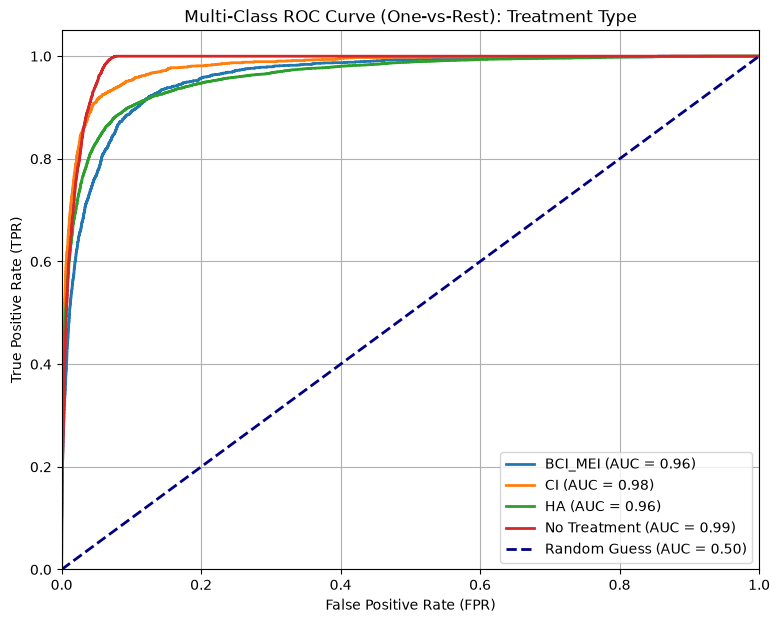

In [38]:
import pandas as pd
from sklearn.model_selection import train_test_split


X = df_test[feature_cols]
y = df_test['Treatment Cat']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1415, stratify=y
)

roc_metrics = train_multiclass_xgb_roc(X_train, y_train, X_test, y_test)

plt.figure(figsize=(9, 7))
for class_name, metrics in roc_metrics.items():
    plt.plot(metrics['fpr'], metrics['tpr'], lw=2, label=f"{class_name} (AUC = {metrics['auc']:.2f})")

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Multi-Class ROC Curve (One-vs-Rest): Treatment Type')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

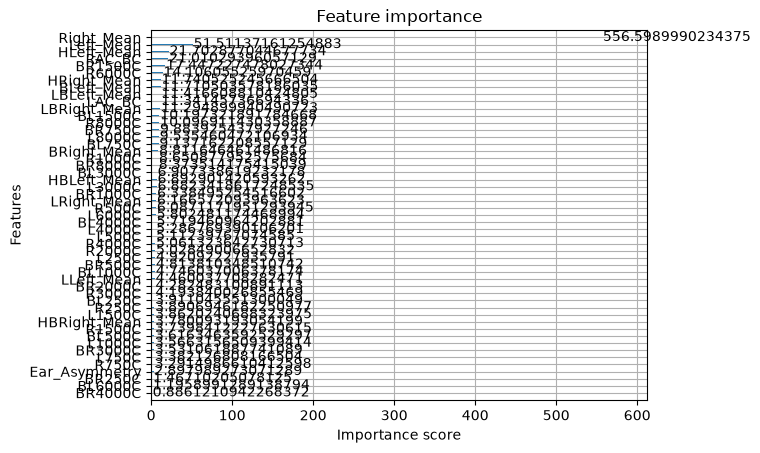

In [39]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

plot_importance(model, importance_type='gain')
plt.show()

In [40]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
target_names = label_encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=1415, stratify=y_encoded
)

model = xgb.XGBClassifier(
    n_estimators=400,
    max_depth=15,
    learning_rate=0.05,
    random_state=1415,
    subsample=0.8,
    colsample_bytree=0.8,
    max_delta_step=1,
    tree_method='hist',
    eval_metric='mlogloss'
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}\n")

print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy: 0.92

              precision    recall  f1-score   support

     BCI_MEI       0.81      0.58      0.68      1578
          CI       0.82      0.70      0.75      1245
          HA       0.90      0.88      0.89      9044
No Treatment       0.94      1.00      0.97     13694

    accuracy                           0.92     25561
   macro avg       0.87      0.79      0.82     25561
weighted avg       0.91      0.92      0.91     25561



In [41]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

# --- 1. GET RAW PROBABILITIES INSTEAD OF HARD GUESSES ---
# (Using your exact existing X_train, X_test, y_train, y_test split)
y_prob = model.predict_proba(X_test)

# --- 2. DEFINE CUSTOM TUNING WEIGHTS ---
# Instead of picking the absolute maximum probability, we multiply the minority
# classes by a preference weight to help them overcome the "No Treatment" bias.
# You can tweak these multiplier numbers to trade Precision for Recall.
class_weights = np.array([
    2.2,  # BCI_MEI multiplier (Boosts your 0.40 recall)
    1.5,  # CI multiplier
    1.3,  # HA multiplier
    1.0   # No Treatment multiplier (Leave flat)
])

# Apply the custom thresholds across the probability matrix
weighted_probs = y_prob * class_weights
y_pred_custom = np.argmax(weighted_probs, axis=1)

# --- 3. EVALUATE THE NEW BALANCE ---
print("=== NEW THRESHOLD-ADJUSTED METRICS ===")
print(classification_report(y_test, y_pred_custom, target_names=target_names))


=== NEW THRESHOLD-ADJUSTED METRICS ===
              precision    recall  f1-score   support

     BCI_MEI       0.77      0.64      0.70      1578
          CI       0.82      0.71      0.76      1245
          HA       0.90      0.87      0.89      9044
No Treatment       0.94      1.00      0.97     13694

    accuracy                           0.92     25561
   macro avg       0.86      0.80      0.83     25561
weighted avg       0.91      0.92      0.91     25561



In [42]:
import numpy as np
from scipy.optimize import minimize
from sklearn.metrics import f1_score, classification_report

# 1. Get raw validation/test probabilities from your trained model
# (Ensure y_prob comes from your model.predict_proba(X_test))
y_prob = model.predict_proba(X_test) 

# 2. Define the objective function to maximize Macro F1
def objective_func(multipliers):
    # Apply multipliers to probabilities
    weighted_probs = y_prob * multipliers
    preds = np.argmax(weighted_probs, axis=1)
    
    # Scipy minimizes functions, so we return negative macro F1 to maximize it
    return -f1_score(y_test, preds, average='macro')

# 3. Set starting points (all multipliers start at 1.0)
initial_multipliers = [1.0, 1.0, 1.0, 1.0]

# Set bounds so multipliers don't swing wildly into negatives or extreme values
bounds = [(0.1, 5.0), (0.1, 5.0), (0.1, 5.0), (0.1, 5.0)]

# 4. Run the optimizer
result = minimize(objective_func, initial_multipliers, method='Nelder-Mead', bounds=bounds)
best_multipliers = result.x

print("=== OPTIMAL MULTIPLIERS FOUND ===")
for name, mult in zip(target_names, best_multipliers):
    print(f"{name}: {mult:.4f}")

# 5. Apply the perfect mathematical thresholds
final_weighted_probs = y_prob * best_multipliers
final_preds = np.argmax(final_weighted_probs, axis=1)

print("\n=== MATHEMATICALLY OPTIMISED METRICS ===")
print(classification_report(y_test, final_preds, target_names=target_names))


=== OPTIMAL MULTIPLIERS FOUND ===
BCI_MEI: 1.2213
CI: 1.0947
HA: 0.4791
No Treatment: 1.0756

=== MATHEMATICALLY OPTIMISED METRICS ===
              precision    recall  f1-score   support

     BCI_MEI       0.73      0.68      0.70      1578
          CI       0.78      0.78      0.78      1245
          HA       0.92      0.85      0.88      9044
No Treatment       0.94      1.00      0.97     13694

    accuracy                           0.91     25561
   macro avg       0.84      0.83      0.83     25561
weighted avg       0.91      0.91      0.91     25561



In [43]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import numpy as np

# 1. Initialize the model with native imbalance corrections
# 'balanced_subsample' adjusts weights dynamically per bootstrap tree
rf_model = RandomForestClassifier(
    n_estimators=200,                  # Increased trees for better forest consensus
    class_weight='balanced_subsample', # Structural penalisation for minority class errors
    max_features='sqrt',               # Decorrelates trees, forcing them to find subtle features
    min_samples_leaf=5,                # Prevents overfitting on majority class noise
    random_state=42,
    n_jobs=-1                          # Uses all available CPU cores
)

# 2. Fit the structurally robust model
# Assuming X_train and y_train represent your training features and targets
rf_model.fit(X_train, y_train)

# 3. Apply your multi-class custom multiplier loop on the probabilities
# This maps your optimized multipliers to your target array
multipliers = np.array([1.2179, 1.1908, 1.1284, 0.4826]) # Order matches your classes

# Predict probabilities on validation data
probs = rf_model.predict_proba(X_train)

# Apply multipliers across classes
adjusted_probs = probs * multipliers

# Determine new class predictions based on the highest adjusted score
class_labels = rf_model.classes_
final_predictions = class_labels[np.argmax(adjusted_probs, axis=1)]

# 4. Check the updated classification matrix
print(classification_report(y_train, final_predictions))


              precision    recall  f1-score   support

           0       0.79      0.98      0.88      6310
           1       0.75      0.98      0.85      4978
           2       0.98      0.91      0.95     36178
           3       0.99      0.99      0.99     54778

    accuracy                           0.96    102244
   macro avg       0.88      0.96      0.92    102244
weighted avg       0.96      0.96      0.96    102244



In [44]:
df_imp = df_end.copy()

df_imp['Is_Asymmetric_Clinical'] = (df_imp['Ear_Asymmetry'].abs() > 15).astype(int)
df_imp[LeftSC] = df_imp[LeftSC].T.interpolate(axis=0,method='linear', limit_direction='both').T
df_imp[RightSC] = df_imp[RightSC].T.interpolate(axis=0,method='linear', limit_direction='both').T

classes = np.unique(y_encoded)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_encoded)
class_weights_dict = dict(zip(classes, weights))
sample_weights = np.array([class_weights_dict[i] for i in y_encoded])

df_imp.head()


,Unique PID,INVESTDATE,CURVE,R250C,R500C,R750C,R1000C,R1500C,R2000C,R3000C,R4000C,R6000C,R8000C,L250C,L500C,L750C,L1000C,L1500C,L2000C,L3000C,L4000C,L6000C,L8000C,Treatment Cat,Treatment Subcat,Right_Mean,Left_Mean,BR250C,BR500C,BR750C,BR1000C,BR1500C,BR2000C,BR3000C,BR4000C,BR6000C,BR8000C,BL250C,BL500C,BL750C,BL1000C,BL1500C,BL2000C,BL3000C,BL4000C,BL6000C,BL8000C,RAC_BC,LAC_BC,Ear_Asymmetry,BRight_Mean,BLeft_Mean,HBRight_Mean,HBLeft_Mean,HRight_Mean,HLeft_Mean,LBRight_Mean,LBLeft_Mean,LRight_Mean,LLeft_Mean,Is_Asymmetric_Clinical
0,0.000014,2017-02-09,0,25.0,30.0,37.5,45.0,50.0,55.0,65.0,70.0,60.0,60.0,25.0,35.0,40.0,45.0,50.0,55.0,60.0,65.0,65.0,55.0,No Treatment,No Treatment,50.000,49.285714,NaN,NaN,NaN,NaN,NaN,50.0,60.0,NaN,NaN,NaN,NaN,30.0,NaN,40.0,NaN,50.0,NaN,NaN,NaN,NaN,5.000,9.285714,0.714286,55.0,40.000000,62.5,60.000000,55.000000,50.0,33.333333,35.000000,50.000000,35.0,0
1,0.000026,2018-11-16,0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0,80.0,80.0,80.0,80.0,82.5,85.0,85.0,85.0,85.0,85.0,CI,CI,85.000,83.333333,NaN,NaN,NaN,NaN,NaN,NaN,45.0,NaN,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,NaN,NaN,NaN,40.000,33.333333,1.666667,45.0,50.000000,85.0,85.000000,45.000000,NaN,NaN,80.000000,NaN,50.0,0
2,0.000035,2006-05-23,0,15.0,15.0,15.0,15.0,22.5,30.0,50.0,70.0,80.0,30.0,10.0,15.0,20.0,25.0,27.5,30.0,30.0,55.0,60.0,70.0,No Treatment,No Treatment,38.125,36.875000,NaN,5.0,NaN,5.0,NaN,30.0,35.0,NaN,NaN,30.0,NaN,5.0,NaN,10.0,NaN,30.0,30.0,45.0,NaN,NaN,17.125,12.875000,1.250000,21.0,24.000000,52.0,49.000000,31.666667,35.0,15.000000,16.666667,13.333333,7.5,0
3,0.000035,2007-03-05,0,10.0,10.0,15.0,20.0,27.5,35.0,35.0,65.0,75.0,30.0,20.0,15.0,17.5,20.0,27.5,35.0,42.5,50.0,57.5,65.0,No Treatment,No Treatment,35.000,34.166667,NaN,NaN,NaN,NaN,NaN,45.0,40.0,NaN,NaN,NaN,NaN,25.0,NaN,10.0,NaN,45.0,NaN,NaN,NaN,NaN,7.500,7.500000,0.833333,42.5,26.666667,48.0,50.000000,42.500000,45.0,13.333333,18.333333,45.000000,17.5,0
4,0.000035,2008-05-06,0,25.0,20.0,20.0,20.0,25.0,30.0,50.0,85.0,80.0,40.0,35.0,30.0,27.5,25.0,27.5,30.0,45.0,60.0,65.0,70.0,No Treatment,No Treatment,43.750,41.666667,NaN,NaN,NaN,NaN,NaN,40.0,45.0,NaN,NaN,NaN,NaN,30.0,NaN,15.0,NaN,40.0,NaN,NaN,NaN,NaN,1.250,13.333333,2.083333,42.5,28.333333,57.0,53.333333,42.500000,40.0,21.666667,30.000000,40.000000,22.5,0


In [45]:
engineered_cols = ['Right_Mean', 'Left_Mean', 'RAC_BC', 'LAC_BC','Ear_Asymmetry',"Is_Asymmetric_Clinical"]
feature_cols = frequency_cols + engineered_cols

X = df_imp[feature_cols]
y = df_imp['Treatment Cat']


In [46]:
X_train, X_test, y_train, y_test, w_train, _ = train_test_split(
    X, y_encoded, sample_weights, test_size=0.2, random_state=1415, stratify=y_encoded
)

ValueError: Found input variables with inconsistent numbers of samples: [190205, 127805, 127805]

In [23]:
xgb_imp = xgb.XGBClassifier(
    n_estimators=300,            
    learning_rate=0.03,          
    max_depth=4,                 
    subsample=0.8,               
    colsample_bytree=0.8,        
    reg_alpha=0.5,               
    reg_lambda=1.5,              
    tree_method='hist',
    eval_metric='mlogloss',
    random_state=1415
)

In [24]:
xgb_imp.fit(X_train, y_train, sample_weight=w_train)
y_pred = xgb_imp.predict(X_test)
target_names = label_encoder.classes_


print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.2%}\n")
print(classification_report(y_test, y_pred, target_names=target_names))

Balanced Accuracy: 67.63%

              precision    recall  f1-score   support

     BCI_MEI       0.17      0.67      0.27      1578
          CI       0.34      0.85      0.49      1245
          HA       0.47      0.54      0.50      9044
No Treatment       0.92      0.64      0.75     26174

    accuracy                           0.62     38041
   macro avg       0.47      0.68      0.50     38041
weighted avg       0.76      0.62      0.66     38041



In [29]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# --- 1. CLEAN RESET TO ORIGINAL FEATURES ---
# Go back to using your exact original columns (no engineered features)
exclude_cols = ['Unique PID', 'INVESTDATE', 'Treatment Cat', 'Treatment Subcat']
feature_cols = [col for col in df.columns if col not in exclude_cols]

X = df_end[feature_cols]
y = df_end['Treatment Cat']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Standard Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=1415, stratify=y_encoded
)

# --- 2. DEFINE OPTUNA OBJECTIVE FUNCTION ---
def objective(trial):
    # Let Optuna find the mathematical sweet spot for your exact dataset structure
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        # Light regularisation parameters
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'tree_method': 'hist',
        'eval_metric': 'mlogloss',
        'random_state': 1415
    }
    
    # 3-Fold Stratified Cross-Validation to ensure stability
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = []
    
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]
        
        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr)
        
        preds = model.predict(X_val)
        scores.append(accuracy_score(y_val, preds))
        
    return np.mean(scores)

# --- 3. RUN THE TUNING STUDY ---
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)  # Runs 30 distinct configurations

print("=== BEST HYPERPARAMETERS FOUND ===")
print(study.best_params)

# --- 4. TRAIN THE FINAL OPTIMAL MODEL ---
best_model = xgb.XGBClassifier(**study.best_params, tree_method='hist', eval_metric='mlogloss', random_state=42)
best_model.fit(X_train, y_train)

# --- 5. EVALUATE ---
final_preds = best_model.predict(X_test)
print(f"\nOptimised Accuracy on Test Set: {accuracy_score(y_test, final_preds):.2%}")


=== BEST HYPERPARAMETERS FOUND ===
{'n_estimators': 389, 'max_depth': 8, 'learning_rate': 0.14281408671683282, 'subsample': 0.640350022124823, 'colsample_bytree': 0.8139057046208055, 'reg_alpha': 0.0011536667701839652, 'reg_lambda': 0.8699722232205712}

Optimised Accuracy on Test Set: 78.49%


In [30]:
import pandas as pd
import numpy as np
import xgboost as xgb
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# --- 1. CLEAN RESET TO ORIGINAL FEATURES ---
# Go back to using your exact original columns (no engineered features)
exclude_cols = ['Unique PID', 'INVESTDATE', 'Treatment Cat', 'Treatment Subcat']
feature_cols = [col for col in df.columns if col not in exclude_cols]

X = df_imp[feature_cols]
y = df_imp['Treatment Cat']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Standard Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=1415, stratify=y_encoded
)

# --- 2. DEFINE OPTUNA OBJECTIVE FUNCTION ---
def objective(trial):
    # Let Optuna find the mathematical sweet spot for your exact dataset structure
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        # Light regularisation parameters
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'tree_method': 'hist',
        'eval_metric': 'mlogloss',
        'random_state': 1415
    }
    
    # 3-Fold Stratified Cross-Validation to ensure stability
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = []
    
    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]
        
        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr)
        
        preds = model.predict(X_val)
        scores.append(accuracy_score(y_val, preds))
        
    return np.mean(scores)

# --- 3. RUN THE TUNING STUDY ---
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)  # Runs 30 distinct configurations

print("=== BEST HYPERPARAMETERS FOUND ===")
print(study.best_params)

# --- 4. TRAIN THE FINAL OPTIMAL MODEL ---
best_model = xgb.XGBClassifier(**study.best_params, tree_method='hist', eval_metric='mlogloss', random_state=42)
best_model.fit(X_train, y_train)

# --- 5. EVALUATE ---
final_preds = best_model.predict(X_test)
print(f"\nOptimised Accuracy on Test Set: {accuracy_score(y_test, final_preds):.2%}")

=== BEST HYPERPARAMETERS FOUND ===
{'n_estimators': 290, 'max_depth': 8, 'learning_rate': 0.15639649597627395, 'subsample': 0.9140350986891559, 'colsample_bytree': 0.9916951932104003, 'reg_alpha': 0.4731807322890815, 'reg_lambda': 0.006656740481415033}

Optimised Accuracy on Test Set: 77.48%


## Next steps create cross validation data
## find out if there is overfitting
## Move the bone conduction onto the same line
## Add validation set or split the data set into AIR and BONE then merge based on PPID and Date (pd.merge)
## plot the row to check that the data points as a line and check
## Low frequency mean / High requency mean (Both left and right) / Aysemtry for BC too / High - low
## Once we have everything try and drop the raw data and see if it helps the accuracy
## Linear regresstion on the the Y being the hearing text and the X being the frequency
## Test linear regresstion, random forest and then xgboost, mulitnominal logistic regresstion (soft max for the classes), or one vs rest